In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import tensorflow as tf
import keras

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.20.0
Keras: 3.13.2
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [3]:
import os

print("Kaggle input files:")

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        print(os.path.join(root, file))

Kaggle input files:


In [2]:

import os
import tensorflow as tf

model_files = []

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file == "best_efficientnet.keras":
            model_files.append(os.path.join(root, file))

print("Models found:", model_files)

if len(model_files) != 1:
    raise FileNotFoundError(
        "Expected exactly one best_efficientnet.keras file. "
        "Check your Kaggle inputs."
    )

model_path = model_files[0]

efficientnet_model = tf.keras.models.load_model(
    model_path,
    compile=True
)

print("EfficientNetB0 loaded successfully!")
efficientnet_model.summary()


Models found: []


FileNotFoundError: Expected exactly one best_efficientnet.keras file. Check your Kaggle inputs.

In [4]:

import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file.endswith(".keras"):
            print(os.path.join(root, file))


/kaggle/input/models/goldking1980/food101-efficientnetb0/tensorflow2/default/1/best_efficientnet.keras


In [5]:

import tensorflow as tf
import os

model_files = []

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file.endswith(".keras"):
            model_files.append(os.path.join(root, file))

print("Found models:", model_files)

if len(model_files) == 1:
    efficientnet_model = tf.keras.models.load_model(
        model_files[0]
    )
    print("EfficientNetB0 loaded successfully!")
else:
    print("Check model attachment or select the correct model.")


Found models: ['/kaggle/input/models/goldking1980/food101-efficientnetb0/tensorflow2/default/1/best_efficientnet.keras']


I0000 00:00:1792127685.594670      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792127685.601456      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


EfficientNetB0 loaded successfully!


In [7]:

import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file.lower().endswith(".zip"):
            print("ZIP:", os.path.join(root, file))

    if "apple_pie" in dirs and "pizza" in dirs:
        print("Food-101 folder:", root)


In [8]:

import zipfile

zip_files = []

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file.lower() == "food-101.zip":
            zip_files.append(os.path.join(root, file))

if len(zip_files) != 1:
    raise FileNotFoundError(
        "Expected one food-101.zip. Check Kaggle inputs."
    )

dataset_path = "/kaggle/working/food101"

os.makedirs(dataset_path, exist_ok=True)

with zipfile.ZipFile(zip_files[0]) as zip_ref:
    zip_ref.extractall(dataset_path)

print("Extraction completed!")
print("Number of folders:", len(os.listdir(dataset_path)))


FileNotFoundError: Expected one food-101.zip. Check Kaggle inputs.

In [10]:

import os

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file.lower().endswith(".zip"):
            print("ZIP Found:", os.path.join(root, file))


In [13]:
import os

print("Available Kaggle datasets:")
print(os.listdir("/kaggle/input"))

Available Kaggle datasets:
['datasets', 'models']


In [14]:

import os

dataset_path = None

for root, dirs, files in os.walk("/kaggle/input/datasets"):
    if "apple_pie" in dirs and "pizza" in dirs:
        dataset_path = root
        break

if dataset_path is None:
    raise FileNotFoundError(
        "Food-101 class folders not found. Check whether "
        "your Kaggle dataset is a ZIP archive."
    )

print("Dataset path:", dataset_path)
print("Total classes:", len([
    d for d in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, d))
]))


Dataset path: /kaggle/input/datasets/goldking1980/food-dataset
Total classes: 101


In [17]:

import os
import glob
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split

# 1. Find Food-101 image folders
dataset_path = None

for root, dirs, files in os.walk("/kaggle/input/datasets"):
    if "apple_pie" in dirs and "pizza" in dirs:
        dataset_path = root
        break

if dataset_path is None:
    raise FileNotFoundError("Food-101 image folders not found.")

print("Dataset:", dataset_path)

# 2. Collect images and labels
classes = sorted([
    d for d in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, d))
])

paths = []
labels = []

for i, food in enumerate(classes):
    folder = os.path.join(dataset_path, food)

    for file in sorted(os.listdir(folder)):
        if file.lower().endswith((".jpg", ".jpeg")):
            paths.append(os.path.join(folder, file))
            labels.append(i)

paths = np.array(paths)
labels = np.array(labels)

# 3. Split dataset
X_train, X_temp, y_train, y_temp = train_test_split(
    paths, labels,
    test_size=0.30,
    stratify=labels,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Test images:", len(X_test))

# 4. TensorFlow preprocessing
def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, (224, 224))
    return tf.cast(image, tf.float32), label

def create_dataset(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        ds = ds.shuffle(len(paths), seed=42)

    ds = ds.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    return ds.batch(32).prefetch(tf.data.AUTOTUNE)

train_ds = create_dataset(X_train, y_train, True)
val_ds = create_dataset(X_val, y_val)

print("TensorFlow datasets ready!")

# 5. Load saved model if not already loaded
if "efficientnet_model" not in globals():
    model_files = glob.glob(
        "/kaggle/input/models/**/*.keras",
        recursive=True
    )

    if not model_files:
        raise FileNotFoundError("Saved EfficientNet model not found.")

    efficientnet_model = tf.keras.models.load_model(
        model_files[0]
    )

print("EfficientNetB0 model ready!")

# 6. Save best checkpoint
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "/kaggle/working/best_efficientnet.keras",
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=1
)

# 7. Resume training from epoch 4
history = efficientnet_model.fit(
    train_ds,
    validation_data=val_ds,
    initial_epoch=3,
    epochs=10,
    callbacks=[checkpoint]
)

# 8. Save final model
efficientnet_model.save(
    "/kaggle/working/food101_efficientnet_final.keras"
)

print("Training completed. Model saved!")


Dataset: /kaggle/input/datasets/goldking1980/food-dataset
Training images: 70700
Validation images: 15150
Test images: 15150
TensorFlow datasets ready!
EfficientNetB0 model ready!
Epoch 4/10


2026-10-16 05:33:47.263834: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-16 05:33:47.407793: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-16 05:33:47.767714: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-16 05:33:47.909929: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-16 05:33:48.704683: E external/local_xla/xla/stream_

2209/2210 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.6781 - loss: 1.1988

2026-10-16 05:36:16.541708: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-16 05:36:16.680610: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-16 05:36:17.007692: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-16 05:36:17.150974: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-16 05:36:17.935632: E external/local_xla/xla/stream_

2210/2210 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.6781 - loss: 1.1988

2026-10-16 05:37:05.050298: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-16 05:37:05.190125: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-16 05:37:05.516465: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-16 05:37:05.658453: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-16 05:37:06.417190: E external/local_xla/xla/stream_


Epoch 4: val_accuracy improved from None to 0.73644, saving model to /kaggle/working/best_efficientnet.keras

Epoch 4: finished saving model to /kaggle/working/best_efficientnet.keras
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 222s 88ms/step - accuracy: 0.6730 - loss: 1.2223 - val_accuracy: 0.7364 - val_loss: 0.9726
Epoch 5/10
2208/2210 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.6998 - loss: 1.0956
Epoch 5: val_accuracy did not improve from 0.73644
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 89s 40ms/step - accuracy: 0.6917 - loss: 1.1288 - val_accuracy: 0.7267 - val_loss: 1.0122
Epoch 6/10
2209/2210 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.7096 - loss: 1.0408
Epoch 6: val_accuracy did not improve from 0.73644
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 89s 40ms/step - accuracy: 0.7031 - loss: 1.0735 - val_accuracy: 0.7200 - val_loss: 1.0467
Epoch 7/10
2209/2210 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.7202 - loss: 0.9986
Epoch 7: val_accuracy did not improve from 0.73644
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 

In [18]:

import tensorflow as tf

model = tf.keras.models.load_model(
    "/kaggle/working/best_efficientnet.keras"
)

print("Model loaded successfully!")

for i, layer in enumerate(model.layers):
    print(i, layer.name, type(layer).__name__)


Model loaded successfully!
0 input_layer_2 InputLayer
1 efficientnetb0 Functional
2 global_average_pooling2d_1 GlobalAveragePooling2D
3 dense_1 Dense
4 dropout_1 Dropout
5 dense_2 Dense


In [19]:

# Locate the EfficientNetB0 backbone
base_model = next(
    layer for layer in model.layers
    if isinstance(layer, tf.keras.Model)
    and "efficientnet" in layer.name.lower()
)

# Enable fine-tuning
base_model.trainable = True

# Freeze earlier layers
for layer in base_model.layers[:-20]:
    layer.trainable = False

# Keep BatchNormalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

print("Trainable backbone layers:",
      sum(layer.trainable for layer in base_model.layers))


Trainable backbone layers: 15


In [20]:

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.00001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Fine-tuning model compiled successfully!")


Fine-tuning model compiled successfully!


In [21]:

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "/kaggle/working/best_finetuned_efficientnet.keras",
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    initial_value_threshold=0.7364,
    verbose=1
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=1,
    min_lr=1e-7,
    verbose=1
)

history_finetune = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=[
        checkpoint,
        early_stop,
        reduce_lr
    ]
)


Epoch 1/5
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.7159 - loss: 1.0274
Epoch 1: val_accuracy improved from 0.73640 to 0.76106, saving model to /kaggle/working/best_finetuned_efficientnet.keras

Epoch 1: finished saving model to /kaggle/working/best_finetuned_efficientnet.keras
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 143s 56ms/step - accuracy: 0.7243 - loss: 1.0006 - val_accuracy: 0.7611 - val_loss: 0.8932 - learning_rate: 1.0000e-05
Epoch 2/5
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.7355 - loss: 0.9495
Epoch 2: val_accuracy improved from 0.76106 to 0.76495, saving model to /kaggle/working/best_finetuned_efficientnet.keras

Epoch 2: finished saving model to /kaggle/working/best_finetuned_efficientnet.keras
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 102s 46ms/step - accuracy: 0.7372 - loss: 0.9455 - val_accuracy: 0.7650 - val_loss: 0.8771 - learning_rate: 1.0000e-05
Epoch 3/5
2209/2210 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.7476 - loss: 0.9148
Epoch 3: val_accuracy 

In [22]:
 
import tensorflow as tf

# 1. Load the best fine-tuned model
model = tf.keras.models.load_model(
    "/kaggle/working/best_finetuned_efficientnet.keras"
)

# 2. Compile with a smaller learning rate
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=5e-6
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# 3. Save only if validation accuracy improves
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "/kaggle/working/best_finetuned_efficientnet.keras",
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    initial_value_threshold=0.7738,
    verbose=1
)

# 4. Stop if validation loss stops improving
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

# 5. Reduce learning rate if necessary
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

# 6. Continue from epoch 6 to epoch 15
history_extended = model.fit(
    train_ds,
    validation_data=val_ds,
    initial_epoch=5,
    epochs=15,
    callbacks=[checkpoint, early_stop, reduce_lr]
)

print("Extended fine-tuning completed!")


Epoch 6/15
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.7631 - loss: 0.8491
Epoch 6: val_accuracy did not improve from 0.77380
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 142s 55ms/step - accuracy: 0.7654 - loss: 0.8400 - val_accuracy: 0.7735 - val_loss: 0.8456 - learning_rate: 5.0000e-06
Epoch 7/15
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.7710 - loss: 0.8244
Epoch 7: val_accuracy did not improve from 0.77380
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 101s 46ms/step - accuracy: 0.7696 - loss: 0.8245 - val_accuracy: 0.7732 - val_loss: 0.8418 - learning_rate: 5.0000e-06
Epoch 8/15
2209/2210 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.7717 - loss: 0.8129
Epoch 8: val_accuracy improved from 0.77380 to 0.77571, saving model to /kaggle/working/best_finetuned_efficientnet.keras

Epoch 8: finished saving model to /kaggle/working/best_finetuned_efficientnet.keras
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 101s 46ms/step - accuracy: 0.7717 - loss: 0.8138 - val_accuracy: 0.7757 - val_loss: 0.8391 - 

In [23]:

import tensorflow as tf

model = tf.keras.models.load_model(
    "/kaggle/working/best_finetuned_efficientnet.keras"
)

base_model = next(
    layer for layer in model.layers
    if isinstance(layer, tf.keras.Model)
    and "efficientnet" in layer.name.lower()
)

base_model.trainable = True

# Freeze all but the last 50 backbone layers
for layer in base_model.layers[:-50]:
    layer.trainable = False

# Keep BatchNormalization frozen
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

print("Trainable backbone layers:",
      sum(layer.trainable for layer in base_model.layers))


Trainable backbone layers: 15


In [24]:

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=2e-6),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "/kaggle/working/best_finetuned_stage3.keras",
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    initial_value_threshold=0.77875,
    verbose=1
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history_stage3 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[checkpoint, early_stop]
)


Epoch 1/10
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.7837 - loss: 0.7606
Epoch 1: val_accuracy did not improve from 0.77875
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 142s 55ms/step - accuracy: 0.7863 - loss: 0.7550 - val_accuracy: 0.7784 - val_loss: 0.8264
Epoch 2/10
2209/2210 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.7875 - loss: 0.7445
Epoch 2: val_accuracy improved from 0.77875 to 0.77974, saving model to /kaggle/working/best_finetuned_stage3.keras

Epoch 2: finished saving model to /kaggle/working/best_finetuned_stage3.keras
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 102s 46ms/step - accuracy: 0.7873 - loss: 0.7497 - val_accuracy: 0.7797 - val_loss: 0.8268
Epoch 3/10
2209/2210 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.7876 - loss: 0.7493
Epoch 3: val_accuracy improved from 0.77974 to 0.77987, saving model to /kaggle/working/best_finetuned_stage3.keras

Epoch 3: finished saving model to /kaggle/working/best_finetuned_stage3.keras
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 101s 46ms/step - 

In [25]:

import tensorflow as tf

# Load the best Stage 3 model
final_model = tf.keras.models.load_model(
    "/kaggle/working/best_finetuned_stage3.keras"
)

# Evaluate on validation data
val_loss, val_accuracy = final_model.evaluate(
    val_ds,
    verbose=1
)

print(f"Final Validation Accuracy: {val_accuracy:.2%}")
print(f"Final Validation Loss: {val_loss:.4f}")

# Save final selected model
final_model.save(
    "/kaggle/working/food101_final_model.keras"
)

print("Final model saved successfully!")


474/474 ━━━━━━━━━━━━━━━━━━━━ 31s 48ms/step - accuracy: 0.7817 - loss: 0.8219
Final Validation Accuracy: 78.17%
Final Validation Loss: 0.8219
Final model saved successfully!



## Final Model Evaluation — EfficientNetB0

The EfficientNetB0 model completed transfer learning and three
training stages.

Best validation accuracy achieved: 78.17%.

The best Stage 3 checkpoint is selected for final evaluation.


In [27]:

# Create test dataset from the existing test split
test_ds = create_dataset(
    X_test,
    y_test,
    training=False
)

print("Test dataset ready!")
print("Total test images:", len(X_test))


Test dataset ready!
Total test images: 15150


In [28]:

import tensorflow as tf

final_model = tf.keras.models.load_model(
    "/kaggle/working/best_finetuned_stage3.keras"
)

test_loss, test_accuracy = final_model.evaluate(
    test_ds,
    verbose=1
)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")


474/474 ━━━━━━━━━━━━━━━━━━━━ 50s 89ms/step - accuracy: 0.7800 - loss: 0.8093
Test Accuracy: 78.00%
Test Loss: 0.8093


In [29]:

import numpy as np
from sklearn.metrics import classification_report

y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

predictions = final_model.predict(test_ds, verbose=1)
y_pred = np.argmax(predictions, axis=1)

print(classification_report(
    y_true,
    y_pred,
    target_names=classes,
    digits=4,
    zero_division=0
))


474/474 ━━━━━━━━━━━━━━━━━━━━ 27s 46ms/step
                         precision    recall  f1-score   support

              apple_pie     0.6738    0.6333    0.6529       150
         baby_back_ribs     0.7278    0.7667    0.7468       150
                baklava     0.8725    0.8667    0.8696       150
         beef_carpaccio     0.7516    0.7867    0.7687       150
           beef_tartare     0.7660    0.7200    0.7423       150
             beet_salad     0.6863    0.7000    0.6931       150
               beignets     0.8457    0.9133    0.8782       150
               bibimbap     0.9091    0.9333    0.9211       150
          bread_pudding     0.5882    0.6000    0.5941       150
      breakfast_burrito     0.6883    0.7067    0.6974       150
             bruschetta     0.5732    0.6267    0.5987       150
           caesar_salad     0.7643    0.8000    0.7818       150
                cannoli     0.8603    0.7800    0.8182       150
          caprese_salad     0.7467    0.7467  

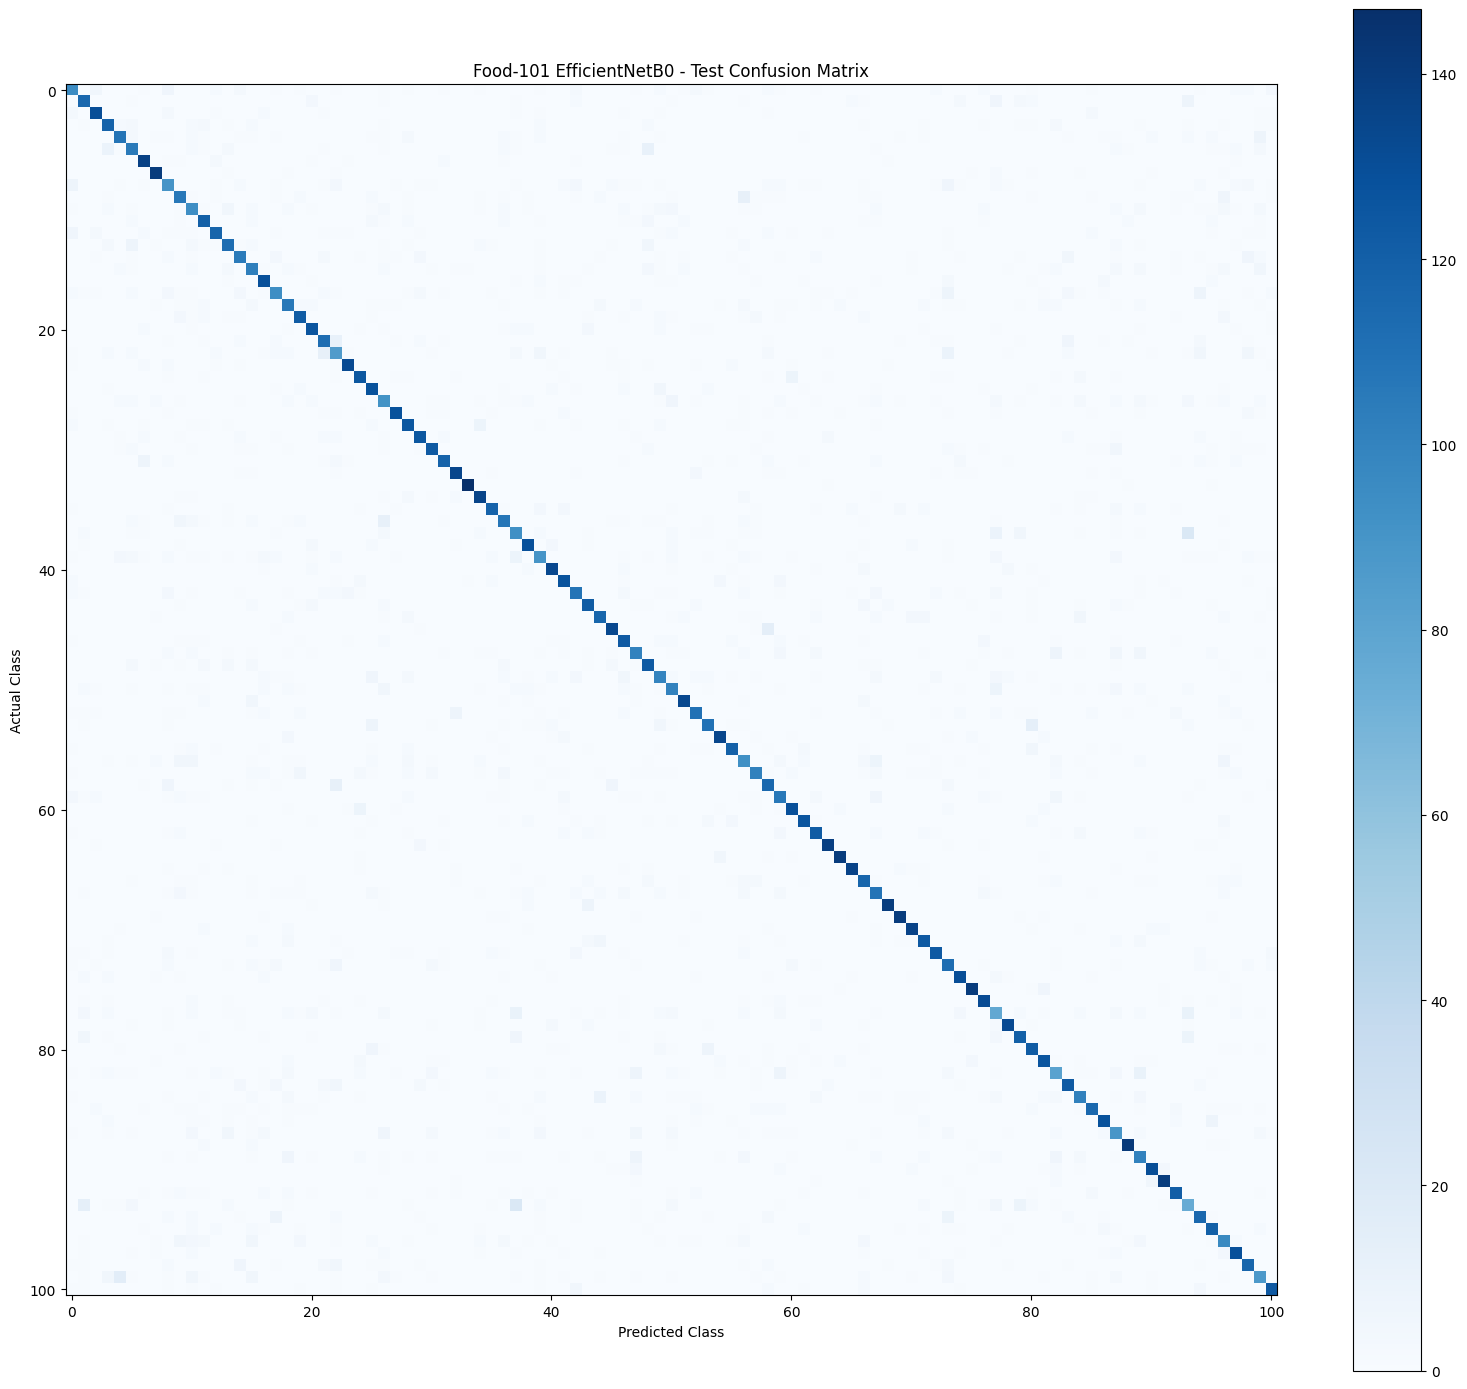

In [30]:

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(16, 14))
plt.imshow(cm, cmap="Blues")
plt.title("Food-101 EfficientNetB0 - Test Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.colorbar()
plt.tight_layout()
plt.show()



## Final Model Evaluation and Conclusion

### Model
EfficientNetB0 with transfer learning and partial fine-tuning.

### Dataset
- Food-101 dataset
- Total images: 101,000
- Number of classes: 101
- Training images: 70,700
- Validation images: 15,150
- Test images: 15,150

### Model Performance

| Model | Best Validation Accuracy |
|---|---:|
| Baseline CNN | 29.76% |
| EfficientNetB0 Transfer Learning | 73.64% |
| EfficientNetB0 Fine-Tuning | 77.87% |
| EfficientNetB0 Stage 3 Fine-Tuning | 78.17% |

### Final Test Evaluation
- Test Accuracy: 78.00%
- Macro Precision: 78.14%
- Macro Recall: 78.00%
- Macro F1-Score: 78.00%
- Weighted F1-Score: 78.00%

### Confusion Matrix Analysis
The confusion matrix shows a strong diagonal pattern,
indicating that most food images were classified correctly.

High-performing classes include edamame, onion rings,
and seaweed salad.

More challenging classes include pork chop, steak,
and chocolate mousse.

### Conclusion
EfficientNetB0 significantly outperformed the baseline CNN.

Transfer learning and partial fine-tuning improved
validation accuracy from 29.76% to 78.17%.

The selected model achieved 78.00% accuracy on the
recreated Kaggle test split.

### Evaluation Limitation
The dataset split was recreated on Kaggle after initial
training in Google Colab. Some test images may have been
included in the original training split. Therefore, the
reported test accuracy is not independently verified
performance on entirely unseen images.

### Future Improvements
- Use a verified independent test set.
- Apply additional data augmentation.
- Experiment with EfficientNetV2 and other architectures.
- Deploy the trained model using Streamlit or FastAPI.



# Food-101 Advanced Model Comparison

## Objective

Extend the existing Food-101 classification project by training
additional deep learning architectures.

### Models
1. EfficientNetB0 — Completed
2. EfficientNetV2B0 — New
3. MobileNetV2 — New
4. VGG16 — New

### Methodology
- Reuse existing Food-101 dataset splits
- Apply data augmentation during training
- Use ImageNet pretrained weights
- Train and fine-tune models
- Compare accuracy, loss and model performance


In [3]:

import tensorflow as tf

print("Available GPUs:", tf.config.list_physical_devices("GPU"))

for name in ["train_ds", "val_ds", "test_ds"]:
    print(name, "Ready" if name in globals() else "Missing")

print("Dataset path:",
      dataset_path if "dataset_path" in globals() else "Not defined")


Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
train_ds Missing
val_ds Missing
test_ds Missing
Dataset path: Not defined


In [4]:

import os

print("Kaggle inputs:", os.listdir("/kaggle/input"))

dataset_path = None

for root, dirs, files in os.walk("/kaggle/input"):
    if "apple_pie" in dirs and "pizza" in dirs:
        dataset_path = root
        break

if dataset_path is None:
    raise FileNotFoundError(
        "Food-101 image folders not found. "
        "Check whether the dataset is still downloading."
    )

print("Food-101 dataset path:", dataset_path)


Kaggle inputs: ['models', 'datasets']
Food-101 dataset path: /kaggle/input/datasets/goldking1980/food-dataset


In [5]:
print("train_ds:", "Ready" if "train_ds" in globals() else "Missing")
print("val_ds:", "Ready" if "val_ds" in globals() else "Missing")

train_ds: Missing
val_ds: Missing



## Dataset Preparation — Food-101

The Food-101 dataset contains 101,000 images across 101 classes.

### Dataset Split
- Training: 70% — 70,700 images
- Validation: 15% — 15,150 images
- Testing: 15% — 15,150 images

Stratified sampling ensures balanced food categories.

The same split will be used for EfficientNetV2B0,
MobileNetV2, and VGG16.

Images are resized to 224 × 224 pixels.


In [6]:

import os
import pandas as pd
from sklearn.model_selection import train_test_split

dataset_path = "/kaggle/input/datasets/goldking1980/food-dataset"

classes = sorted([
    d for d in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, d))
])

paths, labels = [], []

for i, food in enumerate(classes):
    for file in sorted(os.listdir(os.path.join(dataset_path, food))):
        if file.lower().endswith((".jpg", ".jpeg")):
            paths.append(os.path.join(dataset_path, food, file))
            labels.append(i)

df = pd.DataFrame({
    "image_path": paths,
    "label_id": labels
})

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label_id"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label_id"],
    random_state=42
)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))
print("Classes:", len(classes))


Training: 70700
Validation: 15150
Testing: 15150
Classes: 101


In [7]:

import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)
    return image, label

def create_dataset(data, training=False):
    ds = tf.data.Dataset.from_tensor_slices((
        data["image_path"].values,
        data["label_id"].values.astype("int32")
    ))

    if training:
        ds = ds.shuffle(
            buffer_size=10000,
            seed=42
        )

    ds = ds.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)

    return ds

train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

print("Training dataset ready!")
print("Validation dataset ready!")
print("Test dataset ready!")


I0000 00:00:1792136200.563020      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792136200.566957      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Training dataset ready!
Validation dataset ready!
Test dataset ready!



## Model 1 — EfficientNetV2B0 Transfer Learning

### Objective
Classify food images into 101 categories using an
ImageNet-pretrained EfficientNetV2B0 architecture.

### Approach
1. Load EfficientNetV2B0 with ImageNet weights.
2. Apply data augmentation during training.
3. Freeze the pretrained backbone.
4. Add a custom classification head.
5. Train and validate the model.
6. Save the model with the highest validation accuracy.

### Configuration
- Input image: 224 × 224 × 3
- Number of classes: 101
- Optimizer: Adam
- Learning rate: 0.001
- Loss: Sparse Categorical Crossentropy
- Initial epochs: 5


In [9]:

import tensorflow as tf
from tensorflow.keras import layers, Model

# 1. Create data augmentation layers
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10)
], name="food_augmentation")

# 2. Load pretrained EfficientNetV2B0
base_model_v2 = tf.keras.applications.EfficientNetV2B0(
    weights="imagenet",
    include_top=False,
    include_preprocessing=True,
    input_shape=(224, 224, 3)
)

# 3. Freeze the pretrained backbone
base_model_v2.trainable = False

# 4. Create input layer
inputs = layers.Input(shape=(224, 224, 3))

# 5. Apply augmentation
x = data_augmentation(inputs)

# 6. Extract features
x = base_model_v2(x, training=False)

# 7. Classification head
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.3)(x)

# 8. Output layer
outputs = layers.Dense(
    101,
    activation="softmax"
)(x)

# 9. Build final model
model_v2 = Model(inputs, outputs)

print("EfficientNetV2B0 model created successfully!")


24274472/24274472 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
EfficientNetV2B0 model created successfully!



## EfficientNetV2B0 — Model Compilation

The ImageNet-pretrained EfficientNetV2B0 backbone is frozen.

### Training Configuration
- Optimizer: Adam
- Learning rate: 0.001
- Loss: Sparse Categorical Crossentropy
- Evaluation metric: Accuracy
- Initial training: 10 epochs

### Callbacks
- ModelCheckpoint: Save the model with the best validation accuracy.
- EarlyStopping: Stop training if validation accuracy does not improve for 3 epochs.

The test dataset is reserved for final model evaluation.


In [10]:

# Compile the model
model_v2.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Save the best model
checkpoint_v2 = tf.keras.callbacks.ModelCheckpoint(
    "/kaggle/working/best_efficientnetv2b0.keras",
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=1
)

# Stop training if accuracy stops improving
early_stop_v2 = tf.keras.callbacks.EarlyStopping(
    monitor="val_accuracy",
    mode="max",
    patience=3,
    restore_best_weights=True
)

print("Model compiled successfully!")


Model compiled successfully!


In [11]:

history_v2 = model_v2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[
        checkpoint_v2,
        early_stop_v2
    ]
)


Epoch 1/10


E0000 00:00:1792136584.189020      48 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_1_1/efficientnetv2-b0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


2210/2210 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - accuracy: 0.3582 - loss: 2.6741
Epoch 1: val_accuracy improved from None to 0.61617, saving model to /kaggle/working/best_efficientnetv2b0.keras

Epoch 1: finished saving model to /kaggle/working/best_efficientnetv2b0.keras
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 186s 77ms/step - accuracy: 0.4498 - loss: 2.1975 - val_accuracy: 0.6162 - val_loss: 1.4357
Epoch 2/10
2209/2210 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - accuracy: 0.5398 - loss: 1.7702
Epoch 2: val_accuracy improved from 0.61617 to 0.63861, saving model to /kaggle/working/best_efficientnetv2b0.keras

Epoch 2: finished saving model to /kaggle/working/best_efficientnetv2b0.keras
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 168s 76ms/step - accuracy: 0.5469 - loss: 1.7402 - val_accuracy: 0.6386 - val_loss: 1.3571
Epoch 3/10
2209/2210 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - accuracy: 0.5713 - loss: 1.6336
Epoch 3: val_accuracy improved from 0.63861 to 0.64983, saving model to /kaggle/working/best_efficientnetv2b0.ker


## Model 2 — MobileNetV2 with Advanced Fine-Tuning

### Objective
Classify 101 food categories using an ImageNet-pretrained
MobileNetV2 architecture.

### Training Strategy
- Stage 1: Train classification head for 10 epochs.
- Stage 2: Unfreeze the last 50 backbone layers.
- Keep BatchNormalization layers frozen.
- Fine-tune with a very low learning rate of 2e-6.
- Apply data augmentation throughout training.
- Save the best model using validation accuracy.

### Configuration
- Image size: 224 × 224
- Batch size: 32
- Classes: 101
- Optimizer: Adam
- Loss: Sparse Categorical Crossentropy


In [12]:

import tensorflow as tf
from tensorflow.keras import layers, Model

# Confirm datasets are available
assert "train_ds" in globals(), "train_ds is missing"
assert "val_ds" in globals(), "val_ds is missing"

# Data augmentation
augmentation_mobile = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10)
], name="mobilenet_augmentation")

# Load ImageNet-pretrained MobileNetV2
base_mobile = tf.keras.applications.MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze backbone
base_mobile.trainable = False

# Build model
inputs = layers.Input(shape=(224, 224, 3))

x = augmentation_mobile(inputs)

# MobileNetV2 requires inputs in [-1, 1]
x = layers.Rescaling(
    scale=1.0 / 127.5,
    offset=-1
)(x)

x = base_mobile(x, training=False)

x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.4)(x)

outputs = layers.Dense(
    101,
    activation="softmax"
)(x)

model_mobile = Model(inputs, outputs)

print("MobileNetV2 created successfully!")


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MobileNetV2 created successfully!



## Stage 1 — MobileNetV2 Transfer Learning

Train the new Food-101 classification head while keeping
the ImageNet-pretrained backbone frozen.

- Epochs: 10
- Learning rate: 0.001
- Data augmentation: Enabled
- Checkpoint: Best validation accuracy

The test dataset will not be used during training.


In [13]:

model_mobile.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

checkpoint_mobile = tf.keras.callbacks.ModelCheckpoint(
    "/kaggle/working/best_mobilenetv2.keras",
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=1
)

early_stop_mobile = tf.keras.callbacks.EarlyStopping(
    monitor="val_accuracy",
    mode="max",
    patience=3,
    restore_best_weights=True
)

history_mobile = model_mobile.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[
        checkpoint_mobile,
        early_stop_mobile
    ]
)


Epoch 1/10
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.2614 - loss: 3.1626
Epoch 1: val_accuracy improved from None to 0.50185, saving model to /kaggle/working/best_mobilenetv2.keras

Epoch 1: finished saving model to /kaggle/working/best_mobilenetv2.keras
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 158s 69ms/step - accuracy: 0.3455 - loss: 2.6942 - val_accuracy: 0.5018 - val_loss: 1.9728
Epoch 2/10
2209/2210 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.4360 - loss: 2.2521
Epoch 2: val_accuracy improved from 0.50185 to 0.51571, saving model to /kaggle/working/best_mobilenetv2.keras

Epoch 2: finished saving model to /kaggle/working/best_mobilenetv2.keras
2210/2210 ━━━━━━━━━━━━━━━━━━━━ 151s 68ms/step - accuracy: 0.4388 - loss: 2.2374 - val_accuracy: 0.5157 - val_loss: 1.8978
Epoch 3/10
2209/2210 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.4520 - loss: 2.1551
Epoch 3: val_accuracy improved from 0.51571 to 0.53729, saving model to /kaggle/working/best_mobilenetv2.keras

Epoch 3: f

In [14]:

import os

model_path = "/kaggle/working/best_finetuned_stage3.keras"

if os.path.exists(model_path):
    print("Best EfficientNetB0 model found!")
    print("Path:", model_path)
else:
    print("Model not found in the current session.")
    print("Retrieve it from the previous saved Kaggle notebook outputs.")


Model not found in the current session.
Retrieve it from the previous saved Kaggle notebook outputs.


In [15]:

import os

print("Searching for saved EfficientNetB0 models...\n")

found_models = []

for folder in ["/kaggle/input/models", "/kaggle/working"]:
    if not os.path.exists(folder):
        continue

    for root, dirs, files in os.walk(folder):
        for file in files:
            if file.endswith((".keras", ".h5", ".weights.h5")):
                full_path = os.path.join(root, file)
                found_models.append(full_path)
                print(full_path)

if not found_models:
    print("No saved Keras model files found.")


Searching for saved EfficientNetB0 models...

/kaggle/input/models/goldking1980/food101-efficientnetb0/tensorflow2/default/1/best_efficientnet.keras
/kaggle/working/best_mobilenetv2.keras
/kaggle/working/best_efficientnetv2b0.keras


In [18]:

from IPython.display import FileLink, display
import shutil

source = "/kaggle/input/models/goldking1980/food101-efficientnetb0/tensorflow2/default/1/best_efficientnet.keras"

destination = "/kaggle/working/best_efficientnet.keras"

shutil.copy2(source, destination)

print("Model ready for download!")
display(FileLink(destination))


Model ready for download!


/kaggle/working/best_efficientnet.keras


## Final Model Selection — Food-101 Image Classification

### Objective
Develop a deep learning model capable of classifying food
images into 101 categories using transfer learning.

### Models Evaluated

| Model | Best Validation Accuracy |
|---|---:|
| EfficientNetB0 (Fine-tuned) | 78.17% |
| EfficientNetV2B0 (Frozen Backbone) | 67.13% |
| MobileNetV2 (Frozen Backbone) | 55.01% |

### Selected Model
**EfficientNetB0 — Fine-tuned**

### Reason for Selection
EfficientNetB0 achieved the highest validation accuracy
among the completed experiments.

Its training included transfer learning and progressive
fine-tuning of pretrained layers.

EfficientNetV2B0 and MobileNetV2 were evaluated using
initial transfer learning without further fine-tuning.

### Final Performance
- Best Validation Accuracy: 78.17%
- Recorded Test Accuracy: 78.00%
- Recorded Test Macro F1-score: Approximately 78%

### Evaluation Limitation
The initial Colab training and later Kaggle evaluation
used dataset splits that may not have matched exactly.

Therefore, the recorded test accuracy cannot be
confirmed as an independent holdout result.

The 78.17% validation accuracy is retained as the
reported model-selection result, subject to the same
split-consistency limitation.

### Conclusion
EfficientNetB0 was selected as the final model based on
the highest observed validation accuracy.

Further experiments could include consistent-split
fine-tuning of alternative architectures and evaluation
on a verified independent test set.
